# Assignment 6 — Two Agents Sharing Tasks Without Collisions

**Objective:** Develop two agents that share tasks without collisions using simple rules.

Two agents move through the same 2D grid. Each agent has its own task and target. Before moving, each agent checks whether its next position is safe.

## Simple rules used

- Each agent moves one cell at a time toward its own target.
- An agent that reaches its target stops there.
- An agent cannot move into a cell occupied by the other agent.
- If both agents want the same cell, **Agent A gets priority** and Agent B waits.
- If the agents would swap positions, Agent A moves first and Agent B waits.

**Important:** Two agents can use the same cell at different times. That is not a collision. A collision means both agents occupy the same cell at the same time.

In [1]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

## Step 1 — Create the grid and assign tasks

The targets are placed so that the agents use different final areas of the grid. This makes the completed routes easier to understand visually.

In [2]:
rows = 8
cols = 8

# Starting positions
start_a = (0, 0)
start_b = (7, 7)

# Individual targets
target_a = (7, 3)
target_b = (0, 4)

print("Agent A:", start_a, "->", target_a)
print("Agent B:", start_b, "->", target_b)

Agent A: (0, 0) -> (7, 3)
Agent B: (7, 7) -> (0, 4)


## Step 2 — Basic movement rule

The agent first tries to reduce the row difference. Once it reaches the correct row, it moves horizontally toward its target.

In [3]:
def get_next_move(position, target):
    row, col = position
    target_row, target_col = target

    if position == target:
        return position

    # Move vertically toward the target first
    if row < target_row:
        return (row + 1, col)
    elif row > target_row:
        return (row - 1, col)

    # Then move horizontally
    if col < target_col:
        return (row, col + 1)
    elif col > target_col:
        return (row, col - 1)

    return position

## Step 3 — Multi-agent simulation

The important part is the collision check. Both agents decide where they want to go, but their movements are then checked before positions are updated.

In [4]:
def simulate_agents(max_steps=30):
    a = start_a
    b = start_b

    path_a = [a]
    path_b = [b]
    wait_steps = []

    for step in range(max_steps):
        desired_a = get_next_move(a, target_a)
        desired_b = get_next_move(b, target_b)

        new_a = a
        new_b = b

        # If both want the same cell, Agent A gets priority
        if desired_a == desired_b and desired_a != a:
            new_a = desired_a
            new_b = b
            wait_steps.append((step + 1, "Agent B"))

        # Prevent the agents from swapping positions in one step
        elif desired_a == b and desired_b == a:
            new_a = desired_a
            new_b = b
            wait_steps.append((step + 1, "Agent B"))

        else:
            # Agent A checks B's current position
            if desired_a != b:
                new_a = desired_a

            # Agent B checks A's current and new position
            if desired_b != a and desired_b != new_a:
                new_b = desired_b
            elif desired_b != b:
                wait_steps.append((step + 1, "Agent B"))

        # Final safety check: never allow the same cell at the same time
        if new_a == new_b:
            new_b = b
            wait_steps.append((step + 1, "Agent B"))

        a = new_a
        b = new_b

        path_a.append(a)
        path_b.append(b)

        if a == target_a and b == target_b:
            break

    return path_a, path_b, wait_steps


path_a, path_b, wait_steps = simulate_agents()

print("Agent A final position:", path_a[-1])
print("Agent B final position:", path_b[-1])
print("Agent A reached target:", path_a[-1] == target_a)
print("Agent B reached target:", path_b[-1] == target_b)
print("Total simulation steps:", len(path_a) - 1)

Agent A final position: (7, 3)
Agent B final position: (0, 4)
Agent A reached target: True
Agent B reached target: True
Total simulation steps: 10


## Step 4 — Verify that no collision occurred

This checks the agents at every time step, rather than just checking whether their drawn paths overlap.

In [5]:
collision_steps = []

for step in range(min(len(path_a), len(path_b))):
    if path_a[step] == path_b[step]:
        collision_steps.append(step)

if len(collision_steps) == 0:
    print("No collisions detected.")
else:
    print("Collision detected at steps:", collision_steps)

No collisions detected.


## Step 5 — Show the complete paths

The paths may cross or come close in some simulations, but crossing lines do not automatically mean a collision. The time-step check above is what determines whether a real collision occurred.

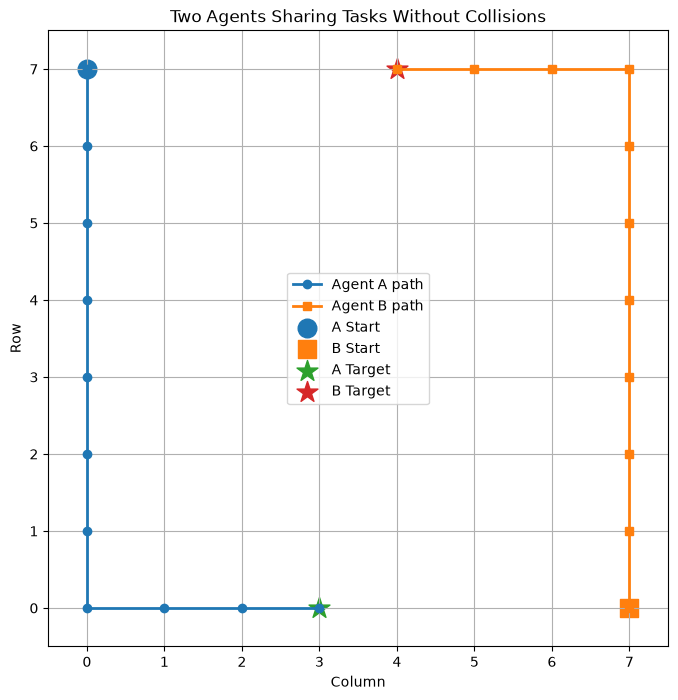

In [6]:
plt.figure(figsize=(8, 8))

x_a = [p[1] for p in path_a]
y_a = [rows - 1 - p[0] for p in path_a]

x_b = [p[1] for p in path_b]
y_b = [rows - 1 - p[0] for p in path_b]

plt.plot(x_a, y_a, marker='o', linewidth=2, label='Agent A path')
plt.plot(x_b, y_b, marker='s', linewidth=2, label='Agent B path')

plt.scatter(start_a[1], rows - 1 - start_a[0], s=180, marker='o', label='A Start')
plt.scatter(start_b[1], rows - 1 - start_b[0], s=180, marker='s', label='B Start')

plt.scatter(target_a[1], rows - 1 - target_a[0], s=250, marker='*', label='A Target')
plt.scatter(target_b[1], rows - 1 - target_b[0], s=250, marker='*', label='B Target')

plt.xticks(range(cols))
plt.yticks(range(rows))
plt.xlim(-0.5, cols - 0.5)
plt.ylim(-0.5, rows - 0.5)
plt.grid(True)
plt.xlabel("Column")
plt.ylabel("Row")
plt.title("Two Agents Sharing Tasks Without Collisions")
plt.legend()
plt.show()

## Step 6 — Time-step animation

This is the clearest way to see collision avoidance. The agents are shown at their actual position for each time step.

In [7]:
for step in range(len(path_a)):
    clear_output(wait=True)

    current_a = path_a[step]
    current_b = path_b[step]

    plt.figure(figsize=(7, 7))

    # Draw travelled paths
    xa = [p[1] for p in path_a[:step + 1]]
    ya = [rows - 1 - p[0] for p in path_a[:step + 1]]
    xb = [p[1] for p in path_b[:step + 1]]
    yb = [rows - 1 - p[0] for p in path_b[:step + 1]]

    plt.plot(xa, ya, marker='o', linewidth=2, label='Agent A path')
    plt.plot(xb, yb, marker='s', linewidth=2, label='Agent B path')

    # Current positions
    plt.scatter(current_a[1], rows - 1 - current_a[0], s=300, marker='o', label='Agent A')
    plt.scatter(current_b[1], rows - 1 - current_b[0], s=300, marker='s', label='Agent B')

    # Targets
    plt.scatter(target_a[1], rows - 1 - target_a[0], s=250, marker='*', label='A Target')
    plt.scatter(target_b[1], rows - 1 - target_b[0], s=250, marker='*', label='B Target')

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.xlim(-0.5, cols - 0.5)
    plt.ylim(-0.5, rows - 0.5)
    plt.grid(True)
    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.title(f"Multi-Agent Simulation — Step {step}")
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2)
    plt.show()

    time.sleep(0.25)

clear_output(wait=True)
print("Simulation complete.")
print("Agent A reached target:", path_a[-1] == target_a)
print("Agent B reached target:", path_b[-1] == target_b)
print("Collisions detected:", len(collision_steps) > 0)

Simulation complete.
Agent A reached target: True
Agent B reached target: True
Collisions detected: False


## Final result

In [8]:
print("Multi-Agent Task Sharing")
print("------------------------")
print("Agent A target reached:", path_a[-1] == target_a)
print("Agent B target reached:", path_b[-1] == target_b)
print("Collisions detected:", len(collision_steps) > 0)
print("Agent A steps:", len(path_a) - 1)
print("Agent B steps:", len(path_b) - 1)
print("Agent B waiting steps:", len([x for x in wait_steps if x[1] == "Agent B"]))

Multi-Agent Task Sharing
------------------------
Agent A target reached: True
Agent B target reached: True
Collisions detected: False
Agent A steps: 10
Agent B steps: 10
Agent B waiting steps: 0
